# Experiment 1: Data Preprocessing, Integration and Analysis

**Dataset:** Heart Disease Dataset (`heart_disease_dataset.csv`)

This notebook adapts the college sample workflow to the supplied heart disease dataset. The target column represents the presence (`1`) or absence (`0`) of heart disease.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix, roc_auc_score
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
# Load the supplied dataset (local upload first; Kaggle path as fallback)
candidate_paths = [
    "/content/heart_disease_dataset (1) (1).csv"
]
file_path = next((p for p in candidate_paths if os.path.exists(p)), None)
if file_path is None:
    raise FileNotFoundError("Place heart_disease_dataset.csv in the notebook working directory.")
df = pd.read_csv(file_path)
print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Dataset shape: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [4]:
print("Columns in dataset:")
print(df.columns.tolist())
print("\nData types:")
print(df.dtypes)

Columns in dataset:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']

Data types:
age           int64
sex           int64
cp            int64
trestbps      int64
chol          int64
fbs           int64
restecg       int64
thalach       int64
exang         int64
oldpeak     float64
slope         int64
ca            int64
thal          int64
target        int64
dtype: object


In [5]:
# Statistical summary
display(df.describe(include="all"))

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000
mean,54.366337,0.683168,0.966997,131.623762,246.264026,0.148515,0.528053,149.646865,0.326733,1.039604,1.399340,0.729373,2.313531,0.544554
std,9.082101,0.466011,1.032052,17.538143,51.830751,0.356198,0.525860,22.905161,0.469794,1.161075,0.616226,1.022606,0.612277,0.498835
min,29.000000,0.000000,0.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,47.500000,0.000000,0.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,55.000000,1.000000,1.000000,130.000000,240.000000,0.000000,1.000000,153.000000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.000000,1.000000,2.000000,140.000000,274.500000,0.000000,1.000000,166.000000,1.000000,1.600000,2.000000,1.000000,3.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


In [6]:
print("First 5 records:")
display(df.head())
print("Last 5 records:")
display(df.tail())

First 5 records:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


Last 5 records:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
298,57,0,0,140,241,0,1,123,1,0.2,1,0,3,0
299,45,1,3,110,264,0,1,132,0,1.2,1,0,3,0
300,68,1,0,144,193,1,1,141,0,3.4,1,2,3,0
301,57,1,0,130,131,0,1,115,1,1.2,1,1,3,0
302,57,0,1,130,236,0,0,174,0,0.0,1,1,2,0


In [7]:
rows, columns = df.shape
print("Total Rows:", rows)
print("Total Columns:", columns)

Total Rows: 303
Total Columns: 14


In [8]:
# Missing value analysis
missing_values = df.isnull().sum()
print("Missing values in each column:")
display(missing_values)

Missing values in each column:


,0
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0


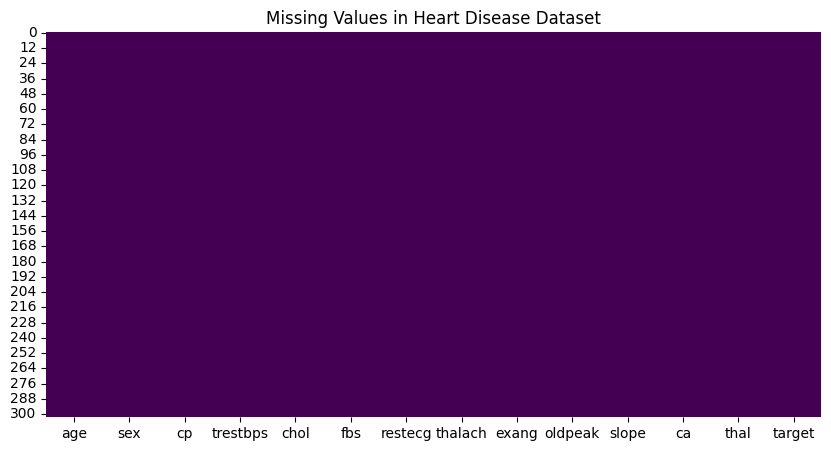

In [9]:
plt.figure(figsize=(10, 5))
sns.heatmap(df.isnull(), cbar=False, cmap="viridis")
plt.title("Missing Values in Heart Disease Dataset")
plt.show()

In [10]:
duplicate_count = df.duplicated().sum()
print("Total duplicate records:", duplicate_count)

Total duplicate records: 1


In [11]:
# Distribution of the target variable
print("Target class counts:")
display(df["target"].value_counts().rename(index={0: "No Heart Disease", 1: "Heart Disease"}))

Target class counts:


,count
target,
Heart Disease,165
No Heart Disease,138


In [12]:
# Explore important numerical attributes
display(df[["age", "trestbps", "chol", "thalach", "oldpeak"]].describe())

,age,trestbps,chol,thalach,oldpeak
count,303.000000,303.000000,303.000000,303.000000,303.000000
mean,54.366337,131.623762,246.264026,149.646865,1.039604
std,9.082101,17.538143,51.830751,22.905161,1.161075
min,29.000000,94.000000,126.000000,71.000000,0.000000
25%,47.500000,120.000000,211.000000,133.500000,0.000000
50%,55.000000,130.000000,240.000000,153.000000,0.800000
75%,61.000000,140.000000,274.500000,166.000000,1.600000
max,77.000000,200.000000,564.000000,202.000000,6.200000


In [13]:
# Create a working copy of the original dataset
df_clean = df.copy()
df_clean.columns = df_clean.columns.str.strip().str.lower()
print("Working copy created.")
print("Columns:", df_clean.columns.tolist())

Working copy created.
Columns: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']


In [14]:
# Remove duplicate records
before_duplicates = len(df_clean)
df_clean = df_clean.drop_duplicates()
after_duplicates = len(df_clean)
print("Records before removing duplicates:", before_duplicates)
print("Records after removing duplicates:", after_duplicates)
print("Duplicates removed:", before_duplicates - after_duplicates)

Records before removing duplicates: 303
Records after removing duplicates: 302
Duplicates removed: 1


In [15]:
# Convert all dataset fields to numeric values where appropriate
for col in df_clean.columns:
    df_clean[col] = pd.to_numeric(df_clean[col], errors="coerce")
print("Data types after conversion:")
print(df_clean.dtypes)

Data types after conversion:
age           int64
sex           int64
cp            int64
trestbps      int64
chol          int64
fbs           int64
restecg       int64
thalach       int64
exang         int64
oldpeak     float64
slope         int64
ca            int64
thal          int64
target        int64
dtype: object


In [16]:
# Handle missing values using median for feature columns
feature_columns = [c for c in df_clean.columns if c != "target"]
for col in feature_columns:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())
df_clean = df_clean.dropna(subset=["target"])
df_clean["target"] = df_clean["target"].astype(int)
print("Missing values handled.")
display(df_clean.isnull().sum())

Missing values handled.


,0
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0


In [17]:
# Validate target labels and remove invalid target records
df_clean = df_clean[df_clean["target"].isin([0, 1])].copy()
print("Valid target records:", len(df_clean))
print(df_clean["target"].value_counts())

Valid target records: 302
target
1    164
0    138
Name: count, dtype: int64


In [18]:
# Check for invalid negative values in measurements that should be non-negative
non_negative_columns = ["age", "trestbps", "chol", "thalach", "oldpeak", "ca"]
for col in non_negative_columns:
    if col in df_clean.columns:
        print(f"{col}: {(df_clean[col] < 0).sum()} negative values")

age: 0 negative values
trestbps: 0 negative values
chol: 0 negative values
thalach: 0 negative values
oldpeak: 0 negative values
ca: 0 negative values


In [19]:
# Create a clean analysis dataset
df_heart = df_clean.copy()
print("Clean dataset created.")
print("Shape:", df_heart.shape)
display(df_heart.head())

Clean dataset created.
Shape: (302, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


## Data Exploration and Visualization

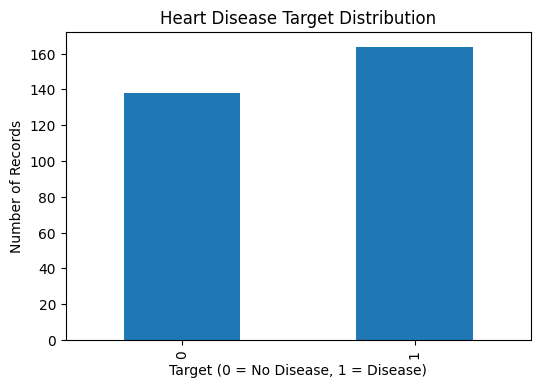

In [20]:
# Heart disease class distribution
plt.figure(figsize=(6, 4))
df_heart["target"].value_counts().sort_index().plot(kind="bar", ax=plt.gca())
plt.title("Heart Disease Target Distribution")
plt.xlabel("Target (0 = No Disease, 1 = Disease)")
plt.ylabel("Number of Records")
plt.show()

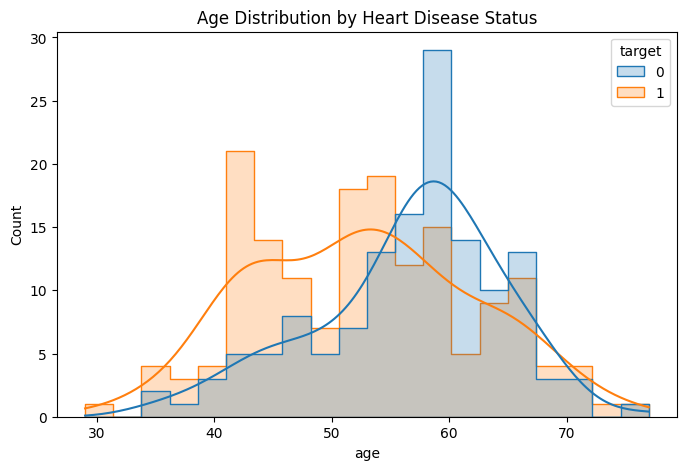

In [21]:
# Age distribution by target class
plt.figure(figsize=(8, 5))
sns.histplot(data=df_heart, x="age", hue="target", bins=20, kde=True, element="step")
plt.title("Age Distribution by Heart Disease Status")
plt.show()

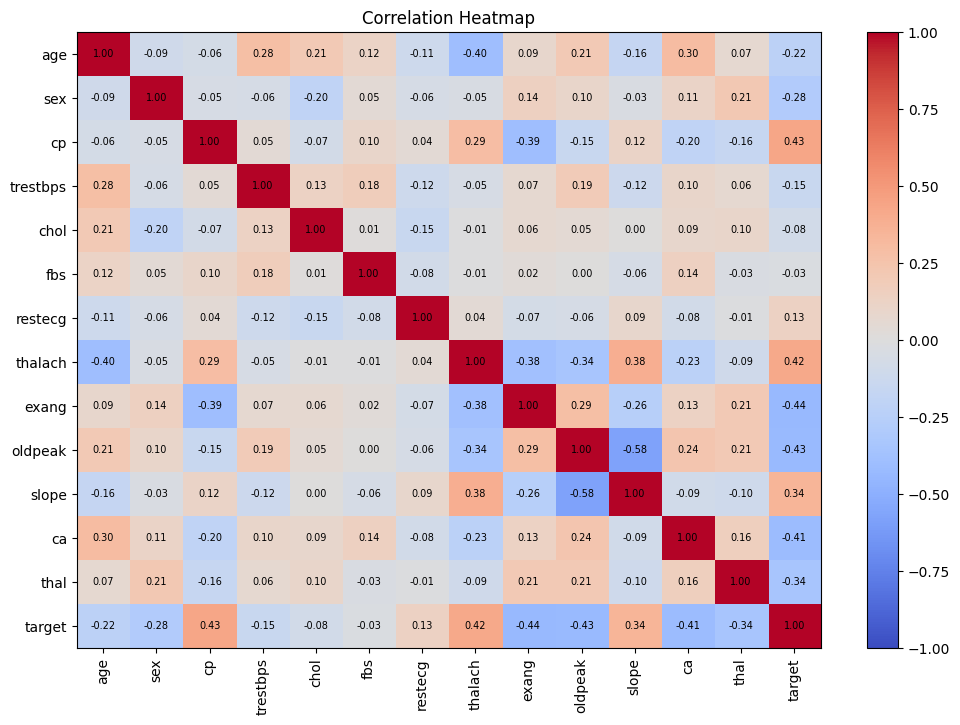

In [22]:
# Correlation heatmap
plt.figure(figsize=(12, 8))
corr = df_heart.corr(numeric_only=True)
plt.imshow(corr, cmap="coolwarm", aspect="auto", vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.columns)), corr.columns)
for r in range(len(corr)):
    for col in range(len(corr.columns)):
        plt.text(col, r, f"{corr.iloc[r, col]:.2f}", ha="center", va="center", fontsize=7)
plt.title("Correlation Heatmap")
plt.show()

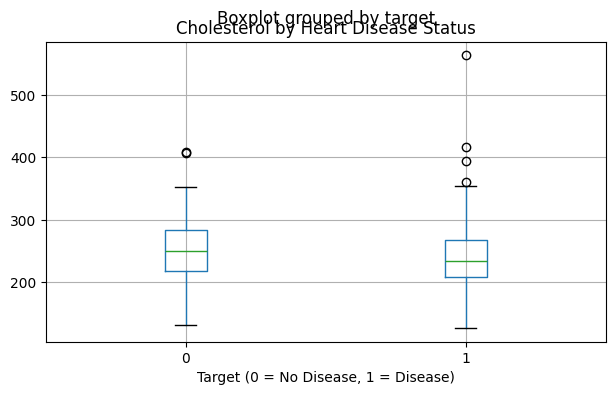

In [23]:
# Boxplot of cholesterol by target
plt.figure(figsize=(7, 4))
df_heart.boxplot(column="chol", by="target", ax=plt.gca())
plt.title("Cholesterol by Heart Disease Status")
plt.xlabel("Target (0 = No Disease, 1 = Disease)")
plt.show()

## Data Integration

In [24]:
# Create a demographic dimension table
demographic_columns = ["age", "sex"]
dim_demographic = df_heart[demographic_columns].drop_duplicates().reset_index(drop=True)
dim_demographic["DemographicKey"] = range(1, len(dim_demographic) + 1)
print("Demographic dimension created.")
display(dim_demographic.head())

Demographic dimension created.


,age,sex,DemographicKey
0,63,1,1
1,37,1,2
2,41,0,3
3,56,1,4
4,57,0,5


In [25]:
# Create a clinical dimension table from clinical measurement fields
clinical_columns = ["trestbps", "chol", "fbs", "restecg", "thalach", "exang", "oldpeak", "slope", "ca", "thal"]
clinical_columns = [c for c in clinical_columns if c in df_heart.columns]
dim_clinical = df_heart[clinical_columns].drop_duplicates().reset_index(drop=True)
dim_clinical["ClinicalKey"] = range(1, len(dim_clinical) + 1)
print("Clinical dimension created.")
display(dim_clinical.head())

Clinical dimension created.


,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,ClinicalKey
0,145,233,1,0,150,0,2.3,0,0,1,1
1,130,250,0,1,187,0,3.5,0,0,2,2
2,130,204,0,0,172,0,1.4,2,0,2,3
3,120,236,0,1,178,0,0.8,2,0,2,4
4,120,354,0,1,163,1,0.6,2,0,2,5


In [26]:
# Integrate demographic and clinical data with the original records
integrated_data = df_heart.merge(dim_demographic, on=demographic_columns, how="left")
integrated_data = integrated_data.merge(dim_clinical, on=clinical_columns, how="left", suffixes=("", "_dim"))
print("Integrated dataset created.")
display(integrated_data.head())
print("Original rows:", len(df_heart), "| Integrated rows:", len(integrated_data))

Integrated dataset created.


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target,DemographicKey,ClinicalKey
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1,2,2
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1,3,3
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1,4,4
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1,5,5


Original rows: 302 | Integrated rows: 302


In [27]:
# Create a heart disease fact table
fact_heart = integrated_data.copy()
fact_heart["RecordKey"] = range(1, len(fact_heart) + 1)
fact_heart = fact_heart[["RecordKey", "DemographicKey", "ClinicalKey", "target"]]
fact_heart = fact_heart.rename(columns={"target": "HeartDisease"})
print("Heart disease fact table created.")
display(fact_heart.head())

Heart disease fact table created.


,RecordKey,DemographicKey,ClinicalKey,HeartDisease
0,1,1,1,1
1,2,2,2,1
2,3,3,3,1
3,4,4,4,1
4,5,5,5,1


In [28]:
# Validate dimension key relationships
print("Valid demographic keys:", fact_heart["DemographicKey"].isin(dim_demographic["DemographicKey"]).all())
print("Valid clinical keys:", fact_heart["ClinicalKey"].isin(dim_clinical["ClinicalKey"]).all())
print("Unique record keys:", fact_heart["RecordKey"].is_unique)

Valid demographic keys: True
Valid clinical keys: True
Unique record keys: True


## Feature Engineering and Data Quality

In [29]:
# Create age groups
df_heart["AgeGroup"] = pd.cut(
    df_heart["age"],
    bins=[0, 30, 40, 50, 60, 70, 120],
    labels=["Under 30", "30-39", "40-49", "50-59", "60-69", "70+"],
    right=False
)
display(df_heart[["age", "AgeGroup", "target"]].head(10))

,age,AgeGroup,target
0,63,60-69,1
1,37,30-39,1
2,41,40-49,1
3,56,50-59,1
4,57,50-59,1
5,57,50-59,1
6,56,50-59,1
7,44,40-49,1
8,52,50-59,1
9,57,50-59,1


In [30]:
# Create cholesterol categories using clinically descriptive labels (exploratory grouping)
df_heart["CholesterolCategory"] = pd.cut(
    df_heart["chol"],
    bins=[-np.inf, 200, 240, np.inf],
    labels=["Desirable range", "Borderline high", "High"]
)
display(df_heart[["chol", "CholesterolCategory", "target"]].head(10))

,chol,CholesterolCategory,target
0,233,Borderline high,1
1,250,High,1
2,204,Borderline high,1
3,236,Borderline high,1
4,354,High,1
5,192,Desirable range,1
6,294,High,1
7,263,High,1
8,199,Desirable range,1
9,168,Desirable range,1


In [31]:
# Summary of heart disease by age group
age_group_summary = df_heart.groupby("AgeGroup", observed=False).agg(
    TotalRecords=("target", "size"),
    HeartDiseaseCases=("target", "sum"),
    DiseaseRate=("target", "mean")
).reset_index()
age_group_summary["DiseaseRate"] = (age_group_summary["DiseaseRate"] * 100).round(2)
display(age_group_summary)

,AgeGroup,TotalRecords,HeartDiseaseCases,DiseaseRate
0,Under 30,1,1,100.00
1,30-39,14,10,71.43
2,40-49,72,50,69.44
3,50-59,125,65,52.00
4,60-69,80,32,40.00
5,70+,10,6,60.00


In [32]:
# Data quality report
print("========== DATA QUALITY REPORT ==========")
print("\nMissing values:")
display(df_heart.isnull().sum())
print("Duplicate records:", df_heart.duplicated().sum())
print("Dataset shape:", df_heart.shape)

========== DATA QUALITY REPORT ==========

Missing values:


,0
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0


Duplicate records: 0
Dataset shape: (302, 16)


In [33]:
# Export cleaned dataset and warehouse tables
output_dir = "/mnt/data"
if not os.path.isdir(output_dir):
    output_dir = "."
df_heart.to_csv(os.path.join(output_dir, "heart_disease_cleaned.csv"), index=False)
fact_heart.to_csv(os.path.join(output_dir, "fact_heart_disease.csv"), index=False)
dim_demographic.to_csv(os.path.join(output_dir, "dim_demographic.csv"), index=False)
dim_clinical.to_csv(os.path.join(output_dir, "dim_clinical.csv"), index=False)
print("Cleaned dataset and dimension/fact tables exported to:", output_dir)

Cleaned dataset and dimension/fact tables exported to: .


## OLAP-Style Analysis

In [34]:
# Roll-up: heart disease cases by age group
rollup_result = df_heart.groupby("AgeGroup", observed=False).agg(
    TotalRecords=("target", "size"),
    HeartDiseaseCases=("target", "sum")
).reset_index()
display(rollup_result)

,AgeGroup,TotalRecords,HeartDiseaseCases
0,Under 30,1,1
1,30-39,14,10
2,40-49,72,50
3,50-59,125,65
4,60-69,80,32
5,70+,10,6


In [35]:
# Drill-down: heart disease cases by age and sex
drilldown_result = df_heart.groupby(["AgeGroup", "sex"], observed=False).agg(
    TotalRecords=("target", "size"),
    HeartDiseaseCases=("target", "sum"),
    DiseaseRate=("target", "mean")
).reset_index()
drilldown_result["DiseaseRate"] = (drilldown_result["DiseaseRate"] * 100).round(2)
display(drilldown_result)

,AgeGroup,sex,TotalRecords,HeartDiseaseCases,DiseaseRate
0,Under 30,0,0,0,NaN
1,Under 30,1,1,1,100.00
2,30-39,0,5,5,100.00
3,30-39,1,9,5,55.56
4,40-49,0,19,18,94.74
5,40-49,1,53,32,60.38
6,50-59,0,34,24,70.59
7,50-59,1,91,41,45.05
8,60-69,0,33,20,60.61
9,60-69,1,47,12,25.53


In [36]:
# Slice: records where target indicates heart disease
slice_result = df_heart[df_heart["target"] == 1]
print("Records with heart disease:", len(slice_result))
display(slice_result.head(10))

Records with heart disease: 164


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target,AgeGroup,CholesterolCategory
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1,60-69,Borderline high
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1,30-39,High
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1,40-49,Borderline high
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1,50-59,Borderline high
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1,50-59,High
5,57,1,0,140,192,0,1,148,0,0.4,1,0,1,1,50-59,Desirable range
6,56,0,1,140,294,0,0,153,0,1.3,1,0,2,1,50-59,High
7,44,1,1,120,263,0,1,173,0,0.0,2,0,3,1,40-49,High
8,52,1,2,172,199,1,1,162,0,0.5,2,0,3,1,50-59,Desirable range
9,57,1,2,150,168,0,1,174,0,1.6,2,0,2,1,50-59,Desirable range


In [37]:
# Dice: filter records by age range and cholesterol
dice_result = df_heart[
    (df_heart["age"].between(40, 60)) &
    (df_heart["chol"] > 240)
]
print("Records aged 40-60 with cholesterol above 240:", len(dice_result))
display(dice_result.head(10))

Records aged 40-60 with cholesterol above 240: 101


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target,AgeGroup,CholesterolCategory
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1,50-59,High
6,56,0,1,140,294,0,0,153,0,1.3,1,0,2,1,50-59,High
7,44,1,1,120,263,0,1,173,0,0.0,2,0,3,1,40-49,High
11,48,0,2,130,275,0,1,139,0,0.2,2,0,2,1,40-49,High
12,49,1,1,130,266,0,1,171,0,0.6,2,0,2,1,40-49,High
14,58,0,3,150,283,1,0,162,0,1.0,2,0,2,1,50-59,High
16,58,0,2,120,340,0,1,172,0,0.0,2,0,2,1,50-59,High
18,43,1,0,150,247,0,1,171,0,1.5,2,0,2,1,40-49,High
33,54,1,2,125,273,0,0,152,0,0.5,0,1,2,1,50-59,High
36,54,0,2,135,304,1,1,170,0,0.0,2,0,2,1,50-59,High


In [38]:
# Pivot: heart disease counts by sex and target
pivot_result = pd.pivot_table(
    df_heart,
    index="sex",
    columns="target",
    values="age",
    aggfunc="count",
    fill_value=0
)
pivot_result = pivot_result.rename(columns={0: "No Heart Disease", 1: "Heart Disease"})
display(pivot_result)

target,No Heart Disease,Heart Disease
sex,,
0,24,72
1,114,92


## Heart Disease Prediction using Random Forest

In [39]:
# Prepare features and target for classification
X = df_heart.drop(columns=["target", "AgeGroup", "CholesterolCategory"], errors="ignore")
y = df_heart["target"]
print("Feature shape:", X.shape)
print("Target distribution:")
display(y.value_counts())

Feature shape: (302, 13)
Target distribution:


,count
target,
1,164
0,138


In [40]:
# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

Training features: (241, 13)
Testing features: (61, 13)


In [41]:
# Train Random Forest classifier
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42,
    class_weight="balanced"
)
rf_model.fit(X_train, y_train)
print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [42]:
# Generate predictions
y_pred = rf_model.predict(X_test)
y_pred_probability = rf_model.predict_proba(X_test)[:, 1]
results = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred,
    "Probability_Heart_Disease": y_pred_probability
})
display(results.head(15))

,Actual,Predicted,Probability_Heart_Disease
0,0,0,0.150709
1,0,0,0.373616
2,0,0,0.031372
3,0,1,0.682041
4,0,1,0.653099
5,0,0,0.230644
6,1,1,0.934359
7,0,0,0.335010
8,1,1,0.858032
9,0,1,0.580965


In [43]:
# Evaluate classification model
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
roc_auc = roc_auc_score(y_test, y_pred_probability)
print("========== MODEL EVALUATION ==========")
print("Accuracy:", round(accuracy * 100, 2), "%")
print("Precision:", round(precision * 100, 2), "%")
print("Recall:", round(recall * 100, 2), "%")
print("F1 Score:", round(f1 * 100, 2), "%")
print("ROC-AUC Score:", round(roc_auc, 4))
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

========== MODEL EVALUATION ==========
Accuracy: 83.61 %
Precision: 78.05 %
Recall: 96.97 %
F1 Score: 86.49 %
ROC-AUC Score: 0.9026

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.68      0.79        28
           1       0.78      0.97      0.86        33

    accuracy                           0.84        61
   macro avg       0.87      0.82      0.83        61
weighted avg       0.86      0.84      0.83        61



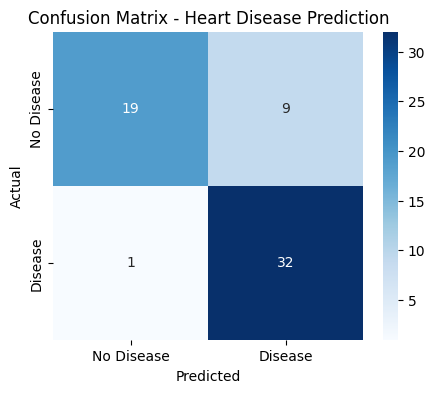

In [44]:
# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["No Disease", "Disease"],
            yticklabels=["No Disease", "Disease"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Heart Disease Prediction")
plt.show()

,Feature,Importance
2,cp,0.180035
12,thal,0.135159
7,thalach,0.109260
9,oldpeak,0.105362
11,ca,0.096291
0,age,0.075139
8,exang,0.072865
4,chol,0.072604
3,trestbps,0.054686
10,slope,0.046569


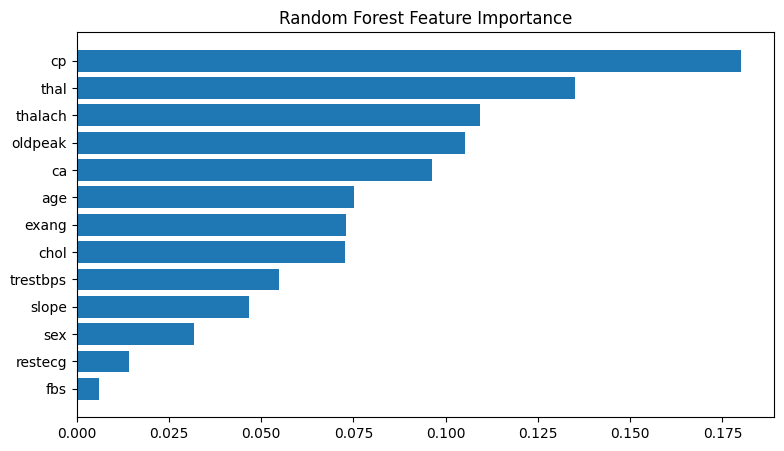

In [45]:
# Feature importance
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
}).sort_values("Importance", ascending=False)
display(feature_importance)
plt.figure(figsize=(9, 5))
plt.barh(feature_importance["Feature"], feature_importance["Importance"])
plt.gca().invert_yaxis()
plt.title("Random Forest Feature Importance")
plt.show()

## Conclusion

The supplied Heart Disease dataset was loaded, explored, cleaned, transformed, integrated into dimension and fact tables, and analyzed using OLAP-style summaries. A Random Forest classifier was trained to predict the dataset's `target` label. Model metrics describe performance on this dataset only and are not a medical diagnostic tool.